<a href="https://colab.research.google.com/github/cs23f012-web/CSL701-20-Machine-Learning-Lab/blob/main/CS20EXP9ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name :
Apurva Santosh Jadhav
Batch :
cs2

Roll Number :
cs20


### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [2]:
# Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load the Palmer Penguins Extended dataset
# Option 1: Load directly via seaborn (standard penguins dataset)
# df = sns.load_dataset('penguins')

# Option 2: Load the extended dataset via a reliable raw GitHub URL
url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
df = pd.read_csv(url)

# Display the first few rows of the dataset
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [11]:
# Handle missing values by dropping missing rows
df_clean = df.dropna().copy()

# Alternatively, if you prefer median imputation:
# df_clean = df.copy()
# feature_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
# df_clean[feature_cols] = df_clean[feature_cols].fillna(df_clean[feature_cols].median())

# Select numerical features (X) and target species (y)
feature_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
X = df_clean[feature_cols]
y = df_clean['species']

# Encode target categorical labels into numerical values (0, 1, 2)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Print dataset details and class mapping
print(f"Original dataset shape: {df.shape}")
print(f"Cleaned dataset shape: {df_clean.shape}\n")
print("Class Mapping:")
for index, class_name in enumerate(le.classes_):
    print(f"  {index} -> {class_name}")

Original dataset shape: (344, 8)
Cleaned dataset shape: (333, 8)

Class Mapping:
  0 -> Adelie
  1 -> Chinstrap
  2 -> Gentoo


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [4]:
# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Output the shape of each split to verify
print(f"Training set features shape: {X_train.shape}")
print(f"Testing set features shape:  {X_test.shape}")
print(f"Training target shape:       {y_train.shape}")
print(f"Testing target shape:        {y_test.shape}")

Training set features shape: (266, 4)
Testing set features shape:  (67, 4)
Training target shape:       (266,)
Testing target shape:        (67,)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [5]:
# Instantiate the DecisionTreeClassifier using the Gini criterion
# (You can also use criterion='entropy')
cart_clf = DecisionTreeClassifier(criterion='gini', random_state=42)

# Fit the CART classifier on the training data
cart_clf.fit(X_train, y_train)

# Predict the species labels for the test set
y_pred_cart = cart_clf.predict(X_test)

# Display a preview of actual vs predicted values
print("Predictions generated successfully!")
print("First 10 actual target values:   ", y_test[:10])
print("First 10 predicted target values:", y_pred_cart[:10])

Predictions generated successfully!
First 10 actual target values:    [2 1 0 2 2 2 1 0 0 2]
First 10 predicted target values: [2 1 0 2 2 2 1 0 0 2]


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Model Accuracy: 95.52%

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.97      0.97      0.97        29
   Chinstrap       0.88      1.00      0.93        14
      Gentoo       1.00      0.92      0.96        24

    accuracy                           0.96        67
   macro avg       0.95      0.96      0.95        67
weighted avg       0.96      0.96      0.96        67



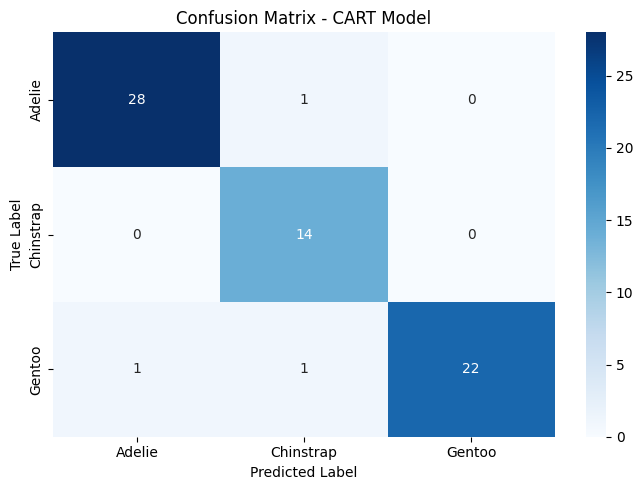

In [6]:
# 1. Calculate Accuracy
acc = accuracy_score(y_test, y_pred_cart)
print(f"CART Model Accuracy: {acc * 100:.2f}%\n")

# 2. Generate Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred_cart, target_names=le.classes_))

# 3. Generate and Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_cart)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)
plt.title('Confusion Matrix - CART Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


CART Model Accuracy: 95.52%

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.97      0.97      0.97        29
   Chinstrap       0.88      1.00      0.93        14
      Gentoo       1.00      0.92      0.96        24

    accuracy                           0.96        67
   macro avg       0.95      0.96      0.95        67
weighted avg       0.96      0.96      0.96        67



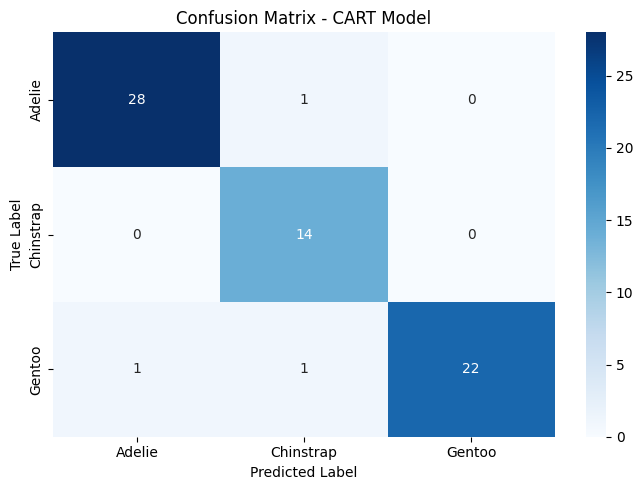

In [7]:
# 1. Calculate Accuracy
acc = accuracy_score(y_test, y_pred_cart)
print(f"CART Model Accuracy: {acc * 100:.2f}%\n")

# 2. Generate Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred_cart, target_names=le.classes_))

# 3. Generate and Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_cart)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)
plt.title('Confusion Matrix - CART Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


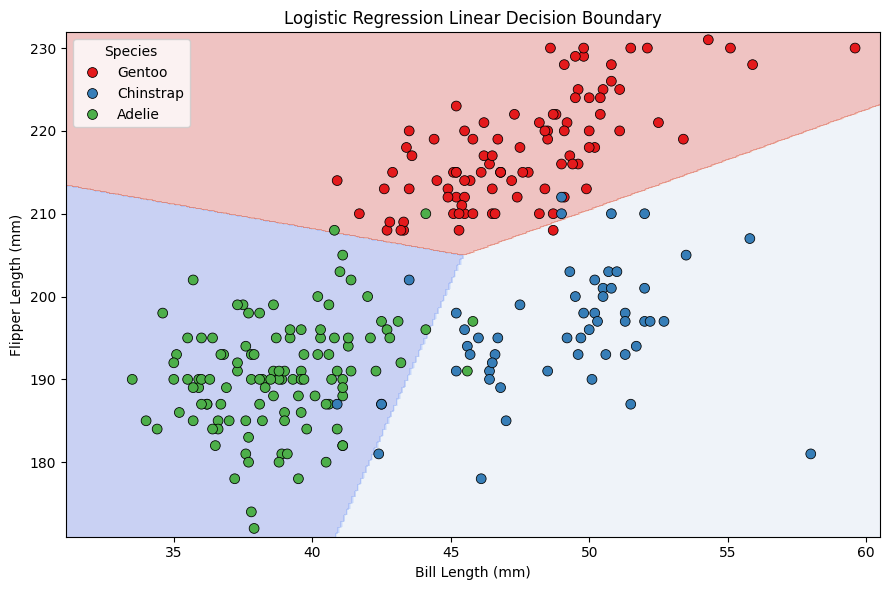

In [8]:
# Select the two features specified for 2D visualization
features_2d = ['bill_length_mm', 'flipper_length_mm']
X_train_2d = X_train[features_2d]
X_test_2d = X_test[features_2d]

# Train Logistic Regression model as a linear baseline
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_2d, y_train)

# Create a mesh grid to plot the decision boundary
x_min, x_max = X[features_2d[0]].min() - 1, X[features_2d[0]].max() + 1
y_min, y_max = X[features_2d[1]].min() - 1, X[features_2d[1]].max() + 1
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.1),
    np.arange(y_min, y_max, 0.1)
)

# Predict class labels across the mesh grid
Z = log_reg.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the linear decision boundary along with data points
plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)

# Scatter plot of training points
sns.scatterplot(
    x=X_train_2d['bill_length_mm'],
    y=X_train_2d['flipper_length_mm'],
    hue=le.inverse_transform(y_train),
    palette='Set1',
    edgecolor='k',
    s=50
)

plt.title('Logistic Regression Linear Decision Boundary')
plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.legend(title='Species', loc='upper left')
plt.tight_layout()
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

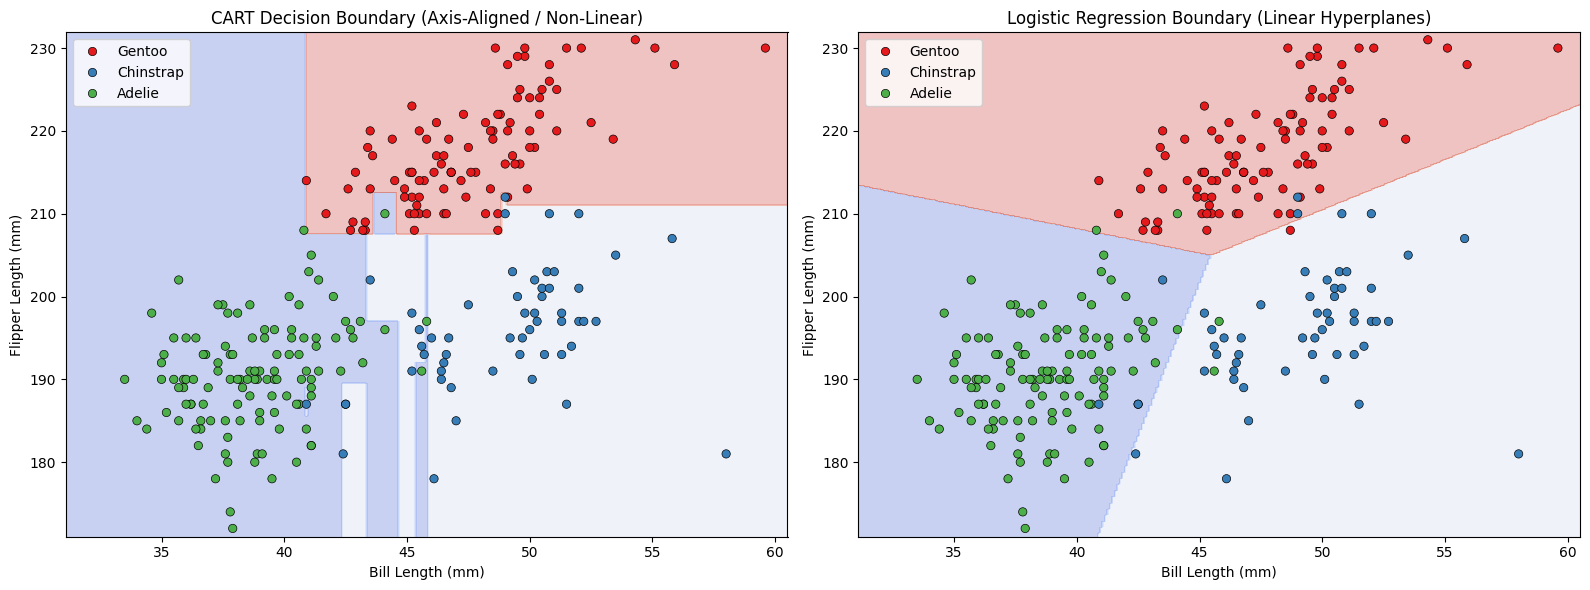

In [9]:
# 1. Prepare 2D features and train both models
features_2d = ['bill_length_mm', 'flipper_length_mm']
X_train_2d = X_train[features_2d]
X_test_2d = X_test[features_2d]

# Fit 2D Decision Tree
cart_2d = DecisionTreeClassifier(criterion='gini', random_state=42)
cart_2d.fit(X_train_2d, y_train)

# Fit 2D Logistic Regression
log_reg_2d = LogisticRegression(max_iter=1000, random_state=42)
log_reg_2d.fit(X_train_2d, y_train)

# 2. Create mesh grid for plotting boundaries
x_min, x_max = X[features_2d[0]].min() - 1, X[features_2d[0]].max() + 1
y_min, y_max = X[features_2d[1]].min() - 1, X[features_2d[1]].max() + 1
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.1),
    np.arange(y_min, y_max, 0.1)
)

# 3. Generate predictions across the mesh grid
grid_points = np.c_[xx.ravel(), yy.ravel()]
grid_df = pd.DataFrame(grid_points, columns=features_2d)  # Avoid feature name warnings

Z_cart = cart_2d.predict(grid_df).reshape(xx.shape)
Z_log = log_reg_2d.predict(grid_df).reshape(xx.shape)

# 4. Create side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot (A): Decision Tree (CART)
axes[0].contourf(xx, yy, Z_cart, alpha=0.3, cmap=plt.cm.coolwarm)
sns.scatterplot(
    data=X_train_2d,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue=le.inverse_transform(y_train),
    palette='Set1',
    edgecolor='k',
    ax=axes[0]
)
axes[0].set_title('CART Decision Boundary (Axis-Aligned / Non-Linear)')
axes[0].set_xlabel('Bill Length (mm)')
axes[0].set_ylabel('Flipper Length (mm)')

# Plot (B): Logistic Regression
axes[1].contourf(xx, yy, Z_log, alpha=0.3, cmap=plt.cm.coolwarm)
sns.scatterplot(
    data=X_train_2d,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue=le.inverse_transform(y_train),
    palette='Set1',
    edgecolor='k',
    ax=axes[1]
)
axes[1].set_title('Logistic Regression Boundary (Linear Hyperplanes)')
axes[1].set_xlabel('Bill Length (mm)')
axes[1].set_ylabel('Flipper Length (mm)')

plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


CART Classifier Accuracy:        95.52%
Logistic Regression Accuracy:   98.51%

--- CART Classifier Report ---
              precision    recall  f1-score   support

      Adelie       0.97      0.97      0.97        29
   Chinstrap       0.88      1.00      0.93        14
      Gentoo       1.00      0.92      0.96        24

    accuracy                           0.96        67
   macro avg       0.95      0.96      0.95        67
weighted avg       0.96      0.96      0.96        67

--- Logistic Regression Report ---
              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        29
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       0.96      1.00      0.98        24

    accuracy                           0.99        67
   macro avg       0.99      0.99      0.99        67
weighted avg       0.99      0.99      0.99        67



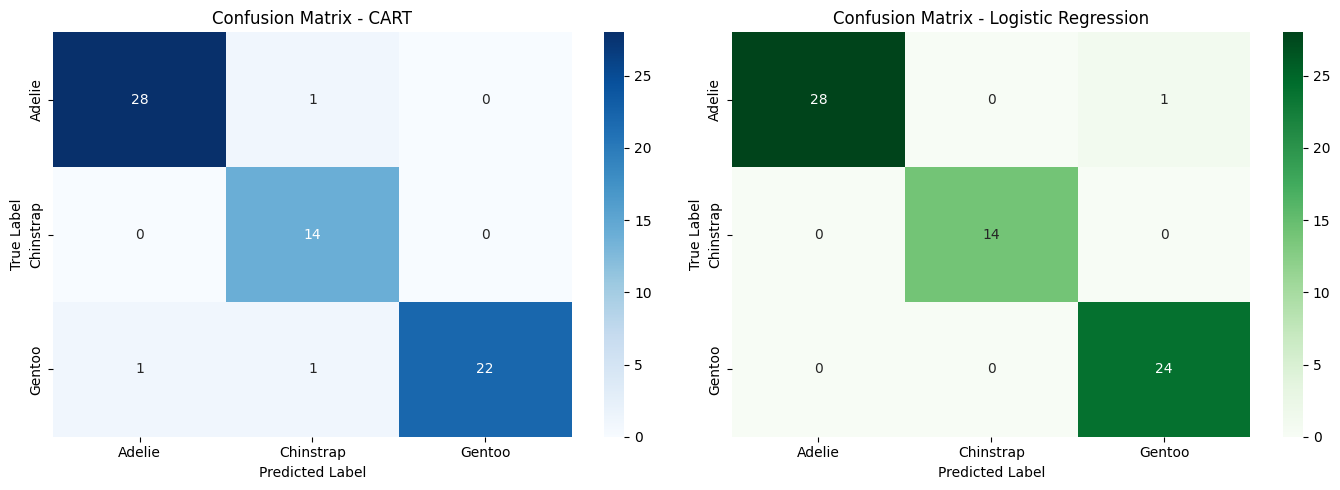

In [12]:
# 1. Train both models on the full feature set (X_train, y_train)
cart_full = DecisionTreeClassifier(criterion='gini', random_state=42)
cart_full.fit(X_train, y_train)
y_pred_cart = cart_full.predict(X_test)

log_reg_full = LogisticRegression(max_iter=1000, random_state=42)
log_reg_full.fit(X_train, y_train)
y_pred_log = log_reg_full.predict(X_test)

# 2. Print Accuracy Scores
acc_cart = accuracy_score(y_test, y_pred_cart)
acc_log = accuracy_score(y_test, y_pred_log)

print("=" * 55)
print(f"CART Classifier Accuracy:        {acc_cart * 100:.2f}%")
print(f"Logistic Regression Accuracy:   {acc_log * 100:.2f}%")
print("=" * 55)

# 3. Print Classification Reports
print("\n--- CART Classifier Report ---")
print(classification_report(y_test, y_pred_cart, target_names=le.classes_))

print("--- Logistic Regression Report ---")
print(classification_report(y_test, y_pred_log, target_names=le.classes_))

# 4. Plot Side-by-Side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_cart = confusion_matrix(y_test, y_pred_cart)
sns.heatmap(cm_cart, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[0])
axes[0].set_title('Confusion Matrix - CART')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

cm_log = confusion_matrix(y_test, y_pred_log)
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Greens',
            xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Confusion Matrix - Logistic Regression')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.